# AP 155 Lab Exercise
---
## Exercise 12: More Integration

_Instructions_: 
- **Problem 1**: Figure: Diffraction Pattern, discussion: Explain the figure
- **Problem 2**: Figure: Gamma Function, discussion: *What is the difference between this version of Monte Carlo and the one we did in the previous session? What should we be careful of when applying Monte Carlo with Importance sampling?*
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Rivera, Kyle Florian
- _Student No._: 2024-16197
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report Figure and Discussion

<center>
  <img src="intensity.png" alt="Intensity"><br>
  <em>Figure 1. Intensity plot of diffraction pattern from a telescope</em>
</center>

> The figure above shows the diffraction pattern from a telescope, exhibiting an Airy disk, with a bright circular spot on the center and concentric rings diminishing in brightness as the rings become farther from the center. This occurs due to the constructive and destructive interference brought by the passage of light waves through the circular aperture of the telescope. Moreover, the intensity plot peaks similarly to the Bessel function as the central maximum corresponds to the peak of the oscillations, where constructive interference is strongest at $r=0$.

<center>
  <img src="gamma.png" alt="Intensity"><br>
  <em>Figure 2. Plot of Gamma function computed using Monte Carlo with importance sampling and scipy.special.gamma</em>
</center>

> The figure above shows the gamma function ($z \in [1,5]$) calculated using Monte Carlo with importance sampling and `scipy.special.gamma`. In the specified domain, it can be seen that the Monte Carlo method resembles the analytic function described by scipy.

---

Discussion:
> Since the bounds of integration spans to infinity, the regular Monte Carlo from the previous session cannot be used as it samples from a uniform distribution, which for this integrand, evaluates to zero as $t \to \infty$, wasting computational resources. As such, importance sampling is used in order to focus the computational effort into the relevant regions of the function being described. By recasting the integral to sample from an exponential probability distribution, $p(t) = e^{-t}$, the method naturally handles the infinite upper bound and perfectly captures the exponential decay of the integrand.
>
> However, when using importance sampling, the distribution to be used must be chosen carefully as if it decays faster or fails to sample the relevant regions of the integrand, rare samples are weighted more, leading to increased variance and yielding less accurate integral values.

### Report discussion

1. Explain the figure 
2. What is the difference between this version of Monte Carlo and the one we did in the previous session? What should we be careful of when applying Monte Carlo with Importance sampling? *(see the answer above)*

### Other comments
- No comment

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 1: Diffraction limit of a telescope


Our ability to resolve detail in astronomical observations is limited by the diffraction of light in our telescopes. Light from stars can be treated effectively as coming from a point source at infinity. When such light, with wavelength $\lambda$, passes through the circular aperture of a telescope (which we'll assume to have unit radius) and is focused by the telescope in the focal plane, it produces not a single dot, but a circular diffraction pattern consisting of a central spot surrounded by a series of concentric rings. The intensity of the light in this diffraction pattern is given by


$$I(r) = \left( \frac{J_1(kr)}{kr} \right)^2$$


where $r$ is the distance in the focal plane from the center of the diffraction pattern, $k=2\pi/\lambda$, and $J_1(x)$ is a Bessel function. The Bessel functions $J_m(x)$ are given by


$$J_m(x) = \frac{1}{\pi} \int_0^\pi \cos(m\theta - x\sin\theta) \, d\theta$$


where $m$ is a nonnegative integer and $x\ge0$.

1. Write a Python function `J(m,x)` that calculates the value of $J_m(x)$ using Simpson's rule with $N=1000$ points. Use your function in a program to make a plot, on a single graph, of the Bessel functions $J_0$, $J_1$, and $J_2$ as a function of $x$ from $x=0$ to $x=20$.
2. Make a second program that makes a density plot of the intensity of the circular diffraction pattern of a point light source with $\lambda=500\text{ nm}$, in a square region of the focal plane, using the formula given above. Your picture should cover values of $r$ from zero up to about $1\,\mu\text{m}$.

**Hint 1:** You may find it useful to know that $\lim_{x\to0} J_1(x)/x = \frac{1}{2}$.

**Hint 2:** The central spot in the diffraction pattern is so bright that it may be difficult to see the rings around it on the computer screen. If you run into this problem, a simple way to deal with it is to use one of the other color schemes for density plots described in Section 3.3. The `hot` scheme works well. For a more sophisticated solution to the problem, the `imshow` function has an additional argument `vmax` that allows you to set the value that corresponds to the brightest point in the plot. For instance, if you say `imshow(x,vmax=0.1)`, then elements in `x` with value 0.1, or any greater value, will produce the brightest color on the screen. By lowering the `vmax` value, you can reduce the total range of values between the minimum and maximum brightness, and hence increase the sensitivity of the plot, making subtle details visible. For this exercise a value of `vmax=0.01` appears to work well. (There is also a `vmin` argument that can be used to set the value that corresponds to the dimmest color.)


---

Lets use the defined integration method from the previous exercise

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
class Setup: # we setup this parent class as the other integration proccesses use the same logic 
    def __init__(self, function, start, end, points):
        self.function = function
        self.start = start
        self.end = end
        self.xs = np.linspace(start, end, points)
        self.ys = self.function(self.xs)
        self.dx = (end-start)/(points-1)

    def calculate(self):
        return self.weights*self.ys
        
    def signed(self, show=False):
        signed_area = np.sum(self.calculate())
        if show:
            print(f"Signed Area: {signed_area}")
        return signed_area
    
    def total(self, show=False):
        total_area = np.sum(np.abs(self.calculate()))
        if show:
            print(f"Total Area: {total_area}")
        return total_area
        
class SimpsonThird(Setup):
    def __init__(self, function, start, end, points):
        if points % 2 != 1:
            raise ValueError("must be an odd number of points")
        super().__init__(function, start, end, points)
        coefficients = [4 if i%2 == 1 else 2 for i in range(points)] # set odd indices to 4, set even indeces to 2
        coefficients[0], coefficients[-1] = 1, 1
        self.weights = (self.dx/3)*np.array(coefficients)

In [4]:
from functools import partial

def integrandj(m, x, theta):
    return np.cos(m*theta - x*np.sin(theta))

def J(m, x, samples):
    function = partial(integrandj, m, x) # we use partial so we can fix m and x
    simpson = SimpsonThird(function, 0, np.pi, samples)
    return simpson.signed()/np.pi

bessel = np.vectorize(J) # so we can pass numpy arrays

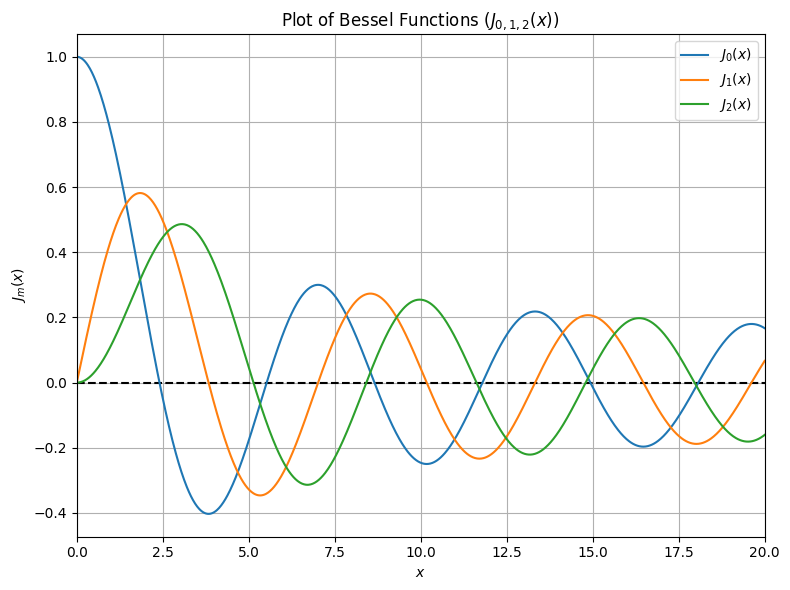

In [5]:
n = 1001
x = np.linspace(0, 20, n)

ys = [bessel(i, x, n) for i in range(0,3)]

fig, ax = plt.subplots(figsize=(8,6))

ax.set_xlabel('$x$')
ax.set_ylabel('$J_m(x)$')
ax.plot(x, np.zeros(1001), color="black", ls='--')
for i in range(0,3):
    ax.plot(x, ys[i], label=f"$J_{i}(x)$")
ax.set_xlim(0, 20)

plt.grid(True)
plt.legend()
plt.title("Plot of Bessel Functions ($J_{0,1,2}(x)$)")
fig.tight_layout()
plt.savefig('bessel.png', dpi=600)
plt.show()

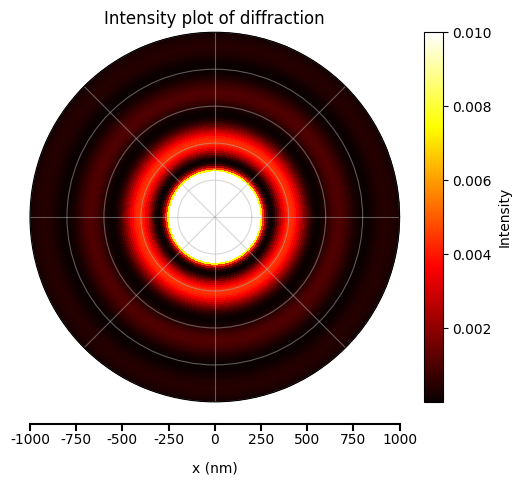

In [6]:
k = 2*np.pi/500e-9
r = np.linspace(0, 1e-6, 100)
n = 1001

# obtaining the values of the function across r
with np.errstate(divide='ignore', invalid='ignore'): # ignores division by 0
    f_r = (bessel(1, k*r, n) / (k*r)) ** 2

# fixed edge case where 0/0 at r = 0
f_r[k*r == 0] = 0.25

# set up theta to revolve around the pole
theta = np.linspace(0, 2 * np.pi, 1000)

R, Theta = np.meshgrid(r, theta)

# revolves r across all theta
Z = np.tile(f_r, (len(theta), 1))

# plots on a polar grid
fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
mesh = ax.pcolormesh(Theta, R, Z, cmap='hot', shading='nearest', vmax=0.01)

# remove the polar decorations
ax.set_rlim(0, 1e-6)
ax.set_yticklabels([])
ax.set_xticklabels([])
ax.grid(alpha=0.5)
# ax.spines['polar'].set_visible(False)   # optional

# axis bar from the center: 0, 250, 500, 750, 1000 nm
rmax = 1e-6
ticks_nm = [-1000, -750, -500, -250, 0, 250, 500, 750, 1000]
y = -0.06          # vertical position below the plot (axes fraction)
tick_len = 0.015

def to_x(nm):
    return 0.5 + (nm * 1e-9 / rmax) * 0.5

ax.plot([to_x(ticks_nm[0]), to_x(ticks_nm[-1])], [y, y], transform=ax.transAxes,
        color='black', linewidth=1.5, solid_capstyle='butt', clip_on=False)

for t in ticks_nm:
    x = to_x(t)
    ax.plot([x, x], [y, y - tick_len], transform=ax.transAxes,
            color='black', linewidth=1.5, clip_on=False)
    ax.text(x, y - tick_len - 0.01, str(t), transform=ax.transAxes,
            ha='center', va='top')

ax.text(to_x(ticks_nm[4]), y - 0.1, "x (nm)", transform=ax.transAxes,
        ha='center', va='top')

# remove gridmarks
# ax.axis('off') 

plt.title("Intensity plot of diffraction")
plt.colorbar(mesh, ax=ax, label='Intensity')
plt.savefig('intensity.png', dpi=600, bbox_inches='tight')
plt.show()

### Problem 2: Integration via Monte Carlo with Importance sampling

Evaluate the gamma function for $z\in [1,5]. $ $$ \Gamma(z) = \int_{0}^{\infty} t^{z-1} e^{-t} \, dt $$ Plot the function using your integration method vs `scipy.special.gamma` (two curves)

Use monte carlo method with importance sampling, by recasting the integral into the form 

$$ \int f(x)dx = \int g(x)p(x)dx, \ \  g(x) = \frac{f(x)}{p(x)}$$


Lets create a class that calculates the integral using importance sampling.

In [7]:
class MonteCarloImportance(Setup):
    def __init__(self, function, p_pdf, p_sampler, points):
        self.function = function
        self.p_pdf = p_pdf
        self.points = points
        
        self.xs = p_sampler(self.points) # sample xs from the probability distribution
        fx = self.function(self.xs) # evaluate f(x) and p(x) at the sampled points
        px = self.p_pdf(self.xs)
        self.ys = fx / px # get g(x)
        
        self.weights = 1.0 / self.points # set weights (1/N) so we can sum it up again (taking the mean)

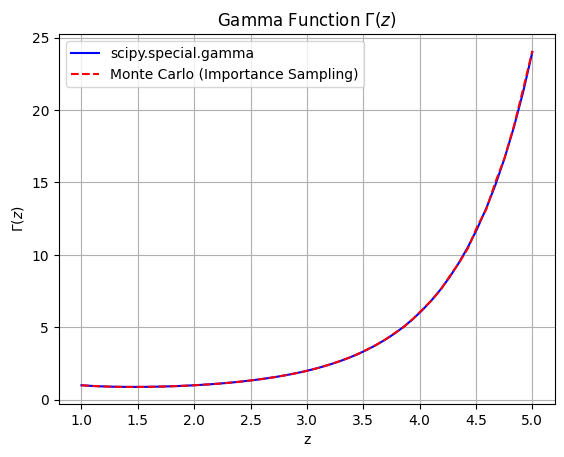

In [8]:
import scipy.special as sp
import matplotlib.pyplot as plt

zs = np.linspace(1, 5, 50)
gamma_mc = []
gamma_scipy = []

p_pdf = lambda t: np.exp(-t) # exponential distribution
p_sampler = lambda n: np.random.exponential(1, n)

N = int(1e6) #sampeles

for z in zs:
    f = lambda t: (t**(z-1)) * np.exp(-t) # get f(t)
    mc = MonteCarloImportance(function=f, p_pdf=p_pdf, p_sampler=p_sampler, points=N) # integrate w monte carlo
    
    gamma_mc.append(mc.signed())
    gamma_scipy.append(sp.gamma(z))

plt.plot(zs, gamma_scipy, label='scipy.special.gamma', color='blue')
plt.plot(zs, gamma_mc, label='Monte Carlo (Importance Sampling)', ls='--', color='red')
plt.title(r'Gamma Function $\Gamma(z)$')
plt.xlabel('z')
plt.ylabel(r'$\Gamma(z)$')
plt.grid(True)
plt.legend()
plt.savefig('gamma.png', dpi=600)
plt.show()